In [1]:
import numpy as np
from rich import print
from contingency import Contingent
import contingency.plots as cntyplt
import matplotlib.pyplot as plt

# from contingency.plots import PR_contour,ROC_contour


rng=np.random.default_rng(2)
np.set_printoptions(formatter={'float_kind':"{:.5g}".format})

# y_true = np.array([0,1,0,0,1,1,0,0]).astype(bool)
y_true = (rng.random(100)>0.6).astype(bool)
# y_prob = np.array([0.1,0.8,0.1,.7,.25,0.68,0.5,0.6])
y_pred = np.where(rng.random(100)<0.05, 1-y_true, y_true).astype(bool)

# y_pred = np.array([0,1,0,1,0,1,0,1]).astype(bool)
y_prob = 10*rng.beta(
    np.where(y_true, 3, 1.),
    np.where(y_true, 1., 3)
)

# M = Contingent(y_pred = y_pred, y_true=y_true)
M = Contingent.from_scalar(y_true, y_prob)

f1_thres,f1_opt = M.optimize('F', include_thres=True)
mcc_thres,mcc_opt = M.optimize('mcc', include_thres=True)

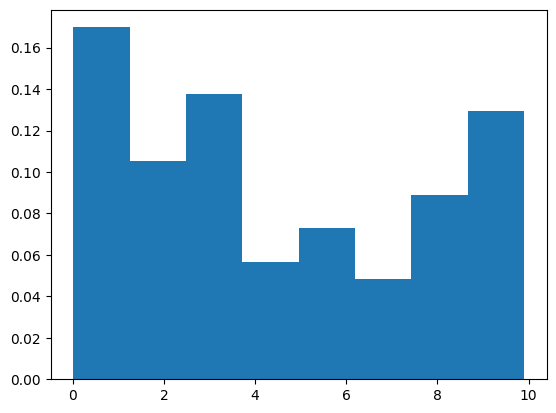

In [2]:
plt.hist(y_prob, bins='auto', density=True);

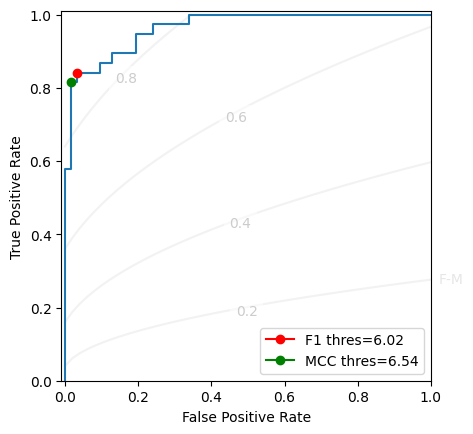

In [10]:
cntyplt.ROC_contour(M.imbalance, 'fm')
plt.plot(1-M.TNR, M.TPR)
plt.plot(f1_opt.FPR, f1_opt.TPR, marker='o', label=f'F1 thres={f1_thres:.2f}', c='r')
plt.plot(mcc_opt.FPR, mcc_opt.TPR, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')

plt.legend()
# plt.gca().spines[['top', 'right']].set_visible(False)

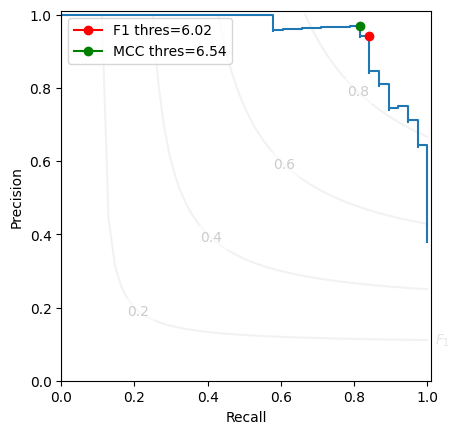

In [9]:
cntyplt.PR_contour(isolines=['f1'])
plt.step(M.recall, M.precision, where='post')


plt.plot(f1_opt.recall, f1_opt.precision, marker='o', label=f'F1 thres={f1_thres:.2f}', c='r')
plt.plot(mcc_opt.recall, mcc_opt.precision, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
# plt.annotate(
plt.legend()

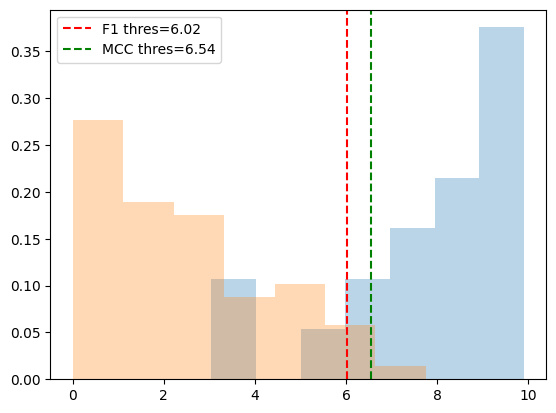

In [5]:
plt.hist(y_prob[y_true], bins='auto', density=True, alpha=0.3)
plt.hist(y_prob[~y_true], bins='auto', density=True, alpha=0.3)
# plt.axvline(0.5, color='0.4', ls='--')
plt.axvline(f1_thres, ls='--', c='r', label=f'F1 thres={f1_thres:.2f}')
plt.axvline(mcc_thres, ls='--', c='g', label=f'MCC thres={mcc_thres:.2f}')
plt.legend()


In [6]:
import matplotlib
from typing import Literal 

def _plot_isoline_func(thres, func, name, ax=None):
    if ax is None:
        ax = plt.gca()
    lines = [(t, *func(t)) for t in thres]
    for t, x, y in lines:
        (l,) = ax.plot(x, y, color="0.95")
        cum_arclen = np.insert(np.cumsum(np.linalg.norm(np.diff(np.column_stack([x,y]), axis=0), axis=1)),0,0)
        mid_x = np.interp(cum_arclen[-1]/2, cum_arclen, x)
        mid_y = np.interp(cum_arclen[-1]/2, cum_arclen, y)
        ax.annotate(
            f"{t:0.1f}",
            # xy=((fp.max()+fp.min())/2, (tp.max()+tp.min())/2),
            xy=(mid_x-0.01, mid_y-0.01),
            color="0.8",
            bbox=dict(facecolor="white", linewidth=0, alpha=0.5),
        )
    ax.annotate(name, xy=(1.01, lines[0][-1][-1] - 0.01), color="0.9")
    
def PR_contour(    
    isolines: list[Literal["f1", "fm"]] | None = ["f1"],
    ax: matplotlib.axes.Axes | None = None
):
    """Generate a nice-looking contour plot for Precision vs. Recall

    For an example, see the [Tutorial](getting-started/02-tutorial/#optional-plotting-utilities)

    REQUIRES optional `contingency[plot]` dependencies! See [Installation](getting-started/01-installation).
    """
    # if not _has_plot:
    #     raise ImportError("Optional contingiency[plot] dependencies required.")

    if ax is None:
        ax = plt.gca()
    thres = np.linspace(0.2, 0.8, num=4)
    
    def _fm_isoline(t):
        recall_fm = np.linspace(t**2,1)
        precis_fm = np.minimum(1,t**2/recall_fm)
        return recall_fm, precis_fm

    def _f1_isoline(t):
        recall_f1 = np.linspace(t / (2 - t),1)
        precis_f1 = np.minimum(t * recall_f1 / (2 * recall_f1 - t), 1)
        return recall_f1, precis_f1

    if isolines is None:
        isolines = []

    if "fm" in isolines:
        _plot_isoline_func(thres, _fm_isoline, r"F-M", ax=ax)
    if "f1" in isolines:
        _plot_isoline_func(thres, _f1_isoline, r"$F_1$", ax=ax)

    ax.set(
        ylim=(0, 1.1),
        xlim=(-0.01, 1.1),
        ylabel="Precision",
        xlabel="Recall",
        aspect=1,
    )
    return ax


# ax.annotate(r"$F_1$", xy=(1.01, 0.2 / (2 - 0.2) - 0.01), color="0.8")
# ax.annotate(r"F-M", xy=(1.01, 0.2**2 - 0.01), color="0.9")
# ax.set(ylim=(0, 1.1), xlim=(0, 1.1), ylabel="Precision", xlabel="Recall")


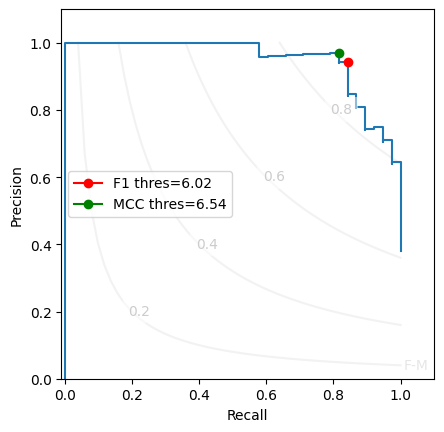

In [7]:
PR_contour(isolines=['fm'])
plt.gca().set_aspect(1)
plt.step(M.recall, M.precision, where='post')


plt.plot(f1_opt.recall, f1_opt.precision, marker='o', label=f'F1 thres={f1_thres:.2f}', c='r')
plt.plot(mcc_opt.recall, mcc_opt.precision, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
# plt.annotate(
plt.legend()

## 1. ROC Space: $TPR(FPR; m, \theta)$

To isolate $TPR$ as an explicit function of $FPR$, target $MCC = m$, and the imbalance ratio $\theta = \frac{N}{P}$, evaluate the standard quadratic equation:

$$TPR(FPR; m, \theta) = \frac{-B + \sqrt{B^2 - 4AC}}{2A}$$

### The Coefficients:
Evaluate these three coefficients sequentially using your independent variable $FPR$ along with constants $m$ and $\theta$:

*   **$A = m^2 + \theta$**
*   **$B = 2\theta \cdot FPR(m^2 - 1) - m^2(\theta + 1)$**
*   **$C = \theta \cdot FPR \left[ FPR(m^2\theta + 1) - m^2(\theta + 1) \right]$**

*Note: The positive root ($+ \sqrt{\dots}$) naturally isolates the valid performance space above the random-guess diagonal line ($m > 0$).*

---

## 2. Precision-Recall Space: $P(R; m, \theta)$

In Precision-Recall space, mapping the imbalance ratio directly into the metric structure yields a clean explicit equation for **Precision ($P$)** as a function of **Recall ($R$)**:

$$P(R; m, \theta) = \frac{2R + m^2\theta + m\sqrt{\theta \left( m^2\theta + 4R(1-R) \right)}}{2R(\theta + 1)}$$

### Vectorized / Python-Friendly Form:
Factoring out the leading baseline scalar transforms the equation into a highly clean form for programming loops or array operations:

$$P(R; m, \theta) = \frac{1}{\theta + 1} \left[ 1 + \frac{m^2\theta + m\sqrt{\theta^2 m^2 + 4\theta R(1-R)}}{2R} \right]$$

---

## 3. Quick Structural Sanity Checks

*   **The Random Baseline ($m = 0$):** If you plug $m = 0$ into the P-R isoline equation, the fractional component inside the brackets collapses to zero, leaving exactly $P(R) = \frac{1}{\theta + 1}$. This matches your horizontal baseline representing a purely random classifier.
*   **The Right-Hand Anchor Point ($R = 1$):** At perfect Recall, the variance term $4\theta R(1-R)$ under the radical drops out completely. The P-R isoline simplifies to a static point at the far right edge of your plot:
$$P(1) = \frac{1 + m^2\theta}{\theta + 1}$$
